In [1]:
!pip install -q rasterio scikit-image

Map size (rows, columns): (1080, 1080)
Lowest and highest point (m): 532.0 1315.314


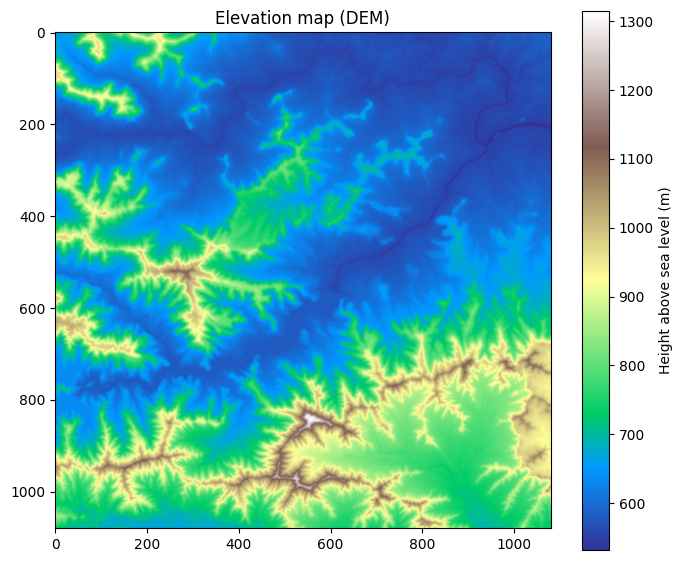

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import rasterio
from rasterio.windows import from_bounds

url = ("https://copernicus-dem-30m.s3.amazonaws.com/"
       "Copernicus_DSM_COG_10_N18_00_E073_00_DEM/"
       "Copernicus_DSM_COG_10_N18_00_E073_00_DEM.tif")

# study area (longitude and latitude boundaries)
W, S, E, N = 73.60, 18.30, 73.90, 18.60

with rasterio.open(url) as src:
    win = from_bounds(W, S, E, N, src.transform)
    dem = src.read(1, window=win).astype("float32")
    transform = src.window_transform(win)
    crs = src.crs

print("Map size (rows, columns):", dem.shape)
print("Lowest and highest point (m):", dem.min(), dem.max())

plt.figure(figsize=(8, 7))
plt.imshow(dem, cmap="terrain")
plt.colorbar(label="Height above sea level (m)")
plt.title("Elevation map (DEM)")
plt.show()

In [3]:
r, c = np.unravel_index(np.argmax(dem), dem.shape)
lon, lat = rasterio.transform.xy(transform, r, c)
print("Highest point at lon, lat:", round(lon, 4), round(lat, 4), "height:", dem[r, c])

Highest point at lon, lat: 73.7546 18.3657 height: 1315.314


Average slope: 9.9 degrees
Steepest: 55.7 degrees


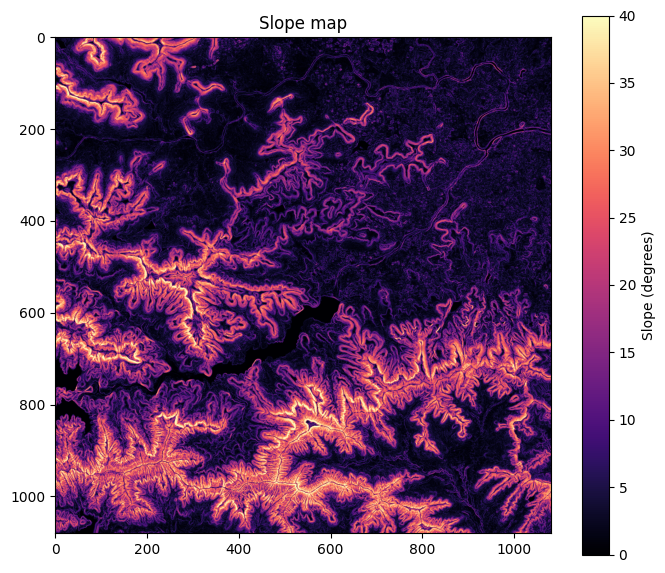

In [4]:
lat = (S + N) / 2
dy = 30.87                                  # metres per pixel, north-south
dx = 30.87 * np.cos(np.radians(lat))        # metres per pixel, east-west

gy, gx = np.gradient(dem, dy, dx)
slope = np.degrees(np.arctan(np.hypot(gx, gy)))

print("Average slope:", round(slope.mean(), 1), "degrees")
print("Steepest:", round(slope.max(), 1), "degrees")

plt.figure(figsize=(8, 7))
plt.imshow(slope, cmap="magma", vmax=40)
plt.colorbar(label="Slope (degrees)")
plt.title("Slope map")
plt.show()

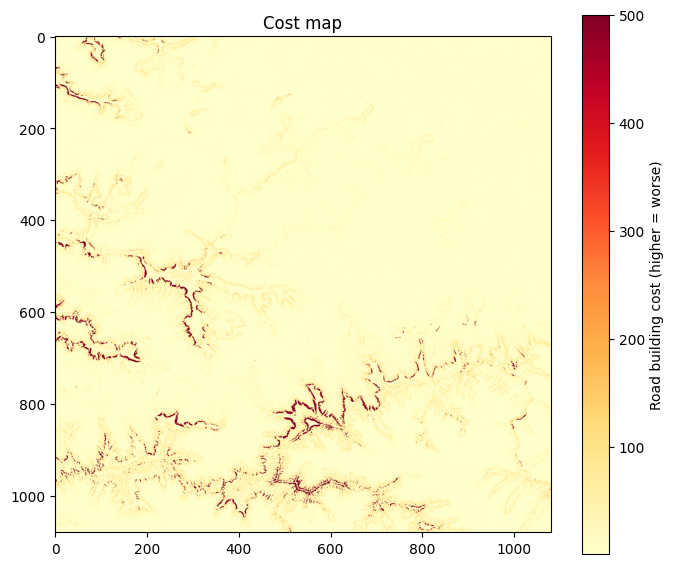

In [5]:
cost = np.select(
    [slope < 5, slope < 10, slope < 15, slope < 25, slope < 35],
    [1,         2,          5,          15,         60],
    default=500
).astype("float32")

plt.figure(figsize=(8, 7))
plt.imshow(cost, cmap="YlOrRd")
plt.colorbar(label="Road building cost (higher = worse)")
plt.title("Cost map")
plt.show()

In [6]:
from rasterio.transform import rowcol
from skimage.graph import route_through_array

# example start and end points (longitude, latitude); change them later
start_lon, start_lat = 73.66, 18.34
end_lon, end_lat = 73.86, 18.56

r1, c1 = rowcol(transform, start_lon, start_lat)
r2, c2 = rowcol(transform, end_lon, end_lat)

path, total_cost = route_through_array(
    cost, (r1, c1), (r2, c2), fully_connected=True, geometric=True
)
path = np.array(path)

def length_m(rows, cols):
    return np.sum(np.hypot(np.diff(rows) * dy, np.diff(cols) * dx))

route_len = length_m(path[:, 0], path[:, 1])
route_slopes = slope[path[:, 0], path[:, 1]]

# straight line for comparison
n = 500
sl_rows = np.linspace(r1, r2, n).astype(int)
sl_cols = np.linspace(c1, c2, n).astype(int)
sl_len = length_m(sl_rows, sl_cols)
sl_slopes = slope[sl_rows, sl_cols]

print(f"{'':22}{'Our route':>12}{'Straight line':>16}")
print(f"{'Length (km)':22}{route_len/1000:>12.1f}{sl_len/1000:>16.1f}")
print(f"{'Average slope (deg)':22}{route_slopes.mean():>12.1f}{sl_slopes.mean():>16.1f}")
print(f"{'Steepest part (deg)':22}{route_slopes.max():>12.1f}{sl_slopes.max():>16.1f}")

                         Our route   Straight line
Length (km)                   38.1            33.1
Average slope (deg)            3.1             8.0
Steepest part (deg)           28.1            41.9


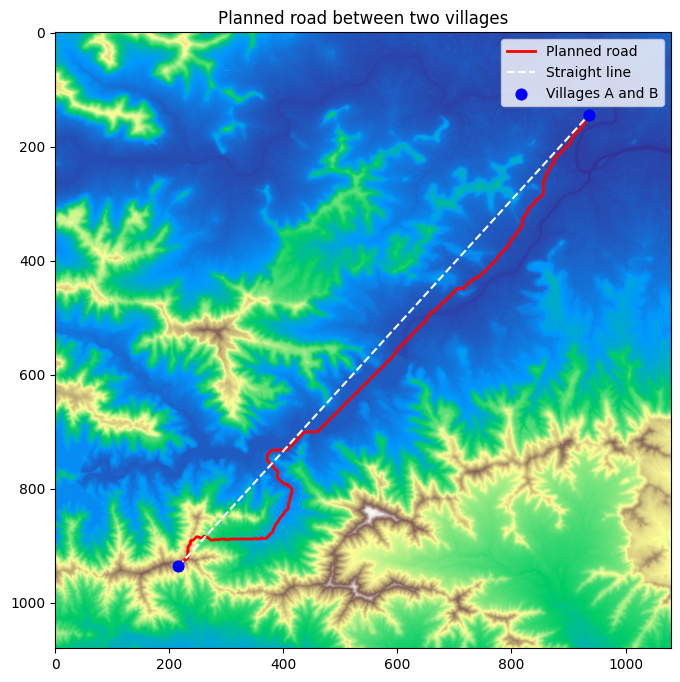

In [7]:
plt.figure(figsize=(9, 8))
plt.imshow(dem, cmap="terrain")
plt.plot(path[:, 1], path[:, 0], color="red", linewidth=2, label="Planned road")
plt.plot([c1, c2], [r1, r2], "w--", linewidth=1.5, label="Straight line")
plt.scatter([c1, c2], [r1, r2], c="blue", s=60, zorder=5, label="Villages A and B")
plt.legend()
plt.title("Planned road between two villages")
plt.savefig("module1_route.png", dpi=150, bbox_inches="tight")
plt.show()

In [8]:
with rasterio.open(
    "dem_pune.tif", "w", driver="GTiff",
    height=dem.shape[0], width=dem.shape[1], count=1,
    dtype="float32", crs=crs, transform=transform
) as dst:
    dst.write(dem, 1)

In [9]:
!pip install -q osmnx

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 104.7/104.7 kB 3.7 MB/s eta 0:00:00


Tree cover    21.5 %
Shrubland     14.6 %
Grassland     29.7 %
Cropland      15.9 %
Built-up      15.7 %
Bare/sparse    0.6 %
Water          2.0 %
Wetland        0.0 %


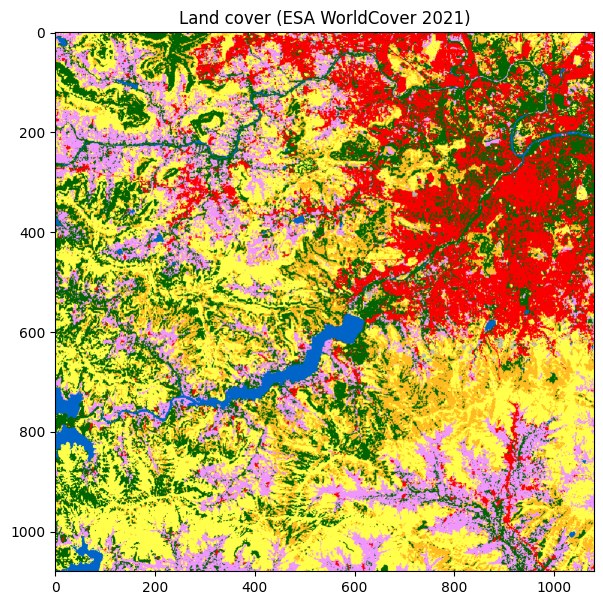

In [10]:
from rasterio.enums import Resampling
import matplotlib.colors as mcolors

lc_url = ("https://esa-worldcover.s3.eu-central-1.amazonaws.com/v200/2021/map/"
          "ESA_WorldCover_10m_2021_v200_N18E072_Map.tif")

with rasterio.open(lc_url) as src:
    win_lc = from_bounds(W, S, E, N, src.transform)
    landcover = src.read(1, window=win_lc, out_shape=dem.shape,
                         resampling=Resampling.nearest)

names = {10: "Tree cover", 20: "Shrubland", 30: "Grassland", 40: "Cropland",
         50: "Built-up", 60: "Bare/sparse", 80: "Water", 90: "Wetland"}
colors = {10: "#006400", 20: "#ffbb22", 30: "#ffff4c", 40: "#f096ff",
          50: "#fa0000", 60: "#b4b4b4", 80: "#0064c8", 90: "#0096a0"}

for code, name in names.items():
    print(f"{name:12} {np.sum(landcover == code) / landcover.size * 100:5.1f} %")

lc_rgb = np.zeros(landcover.shape + (3,))
for code, col in colors.items():
    lc_rgb[landcover == code] = mcolors.to_rgb(col)

plt.figure(figsize=(8, 7))
plt.imshow(lc_rgb)
plt.title("Land cover (ESA WorldCover 2021)")
plt.show()

In [11]:
import osmnx as ox
from rasterio.features import rasterize

def lines_to_mask(tags):
    try:
        gdf = ox.features_from_bbox(bbox=(W, S, E, N), tags=tags)
        gdf = gdf[gdf.geom_type.isin(["LineString", "MultiLineString"])]
        shapes = [(geom, 1) for geom in gdf.geometry]
        mask = rasterize(shapes, out_shape=dem.shape, transform=transform,
                         fill=0, all_touched=True, dtype="uint8").astype(bool)
        print("Found", len(gdf), "features")
        return mask
    except Exception as e:
        print("Could not load:", e)
        return np.zeros(dem.shape, dtype=bool)

river_mask = lines_to_mask({"waterway": ["river"]})
road_mask = lines_to_mask({"highway": ["motorway", "trunk", "primary",
                                       "secondary", "tertiary"]})
print("River pixels:", river_mask.sum(), "| Road pixels:", road_mask.sum())

Found 29 features
Found 4447 features
River pixels: 6806 | Road pixels: 42920


In [12]:
from skimage.graph import route_through_array

# Cost from slope only (same as Module 1)
slope_cost = np.select(
    [slope < 5, slope < 10, slope < 15, slope < 25, slope < 35],
    [1, 2, 5, 15, 60], default=500).astype("float32")

# Extra cost from land type (assumed values)
lc_add = np.zeros(dem.shape, dtype="float32")
for code, add in {10: 6, 20: 1, 30: 0, 40: 2, 50: 15, 60: 0, 80: 200, 90: 10}.items():
    lc_add[landcover == code] = add

cost2 = slope_cost + lc_add
cost2[river_mask] += 30          # crossing a river needs a bridge

USE_EXISTING_ROADS = True        # set to False to ignore existing roads
if USE_EXISTING_ROADS:
    cost2[road_mask] = np.minimum(cost2[road_mask], 1.5)

path1, _ = route_through_array(slope_cost, (r1, c1), (r2, c2),
                               fully_connected=True, geometric=True)
path2, _ = route_through_array(cost2, (r1, c1), (r2, c2),
                               fully_connected=True, geometric=True)
path1, path2 = np.array(path1), np.array(path2)
print("Routes found:", len(path1), "and", len(path2), "pixels")

Routes found: 1010 and 1145 pixels


In [13]:
import pandas as pd

def metrics(rows, cols):
    s = slope[rows, cols]
    lc = landcover[rows, cols]
    rv = river_mask[rows, cols]
    return {
        "Length (km)": round(np.sum(np.hypot(np.diff(rows) * dy, np.diff(cols) * dx)) / 1000, 1),
        "Average slope (deg)": round(s.mean(), 1),
        "Steepest (deg)": round(s.max(), 1),
        "% steeper than 15 deg": round((s > 15).mean() * 100, 1),
        "% through forest": round((lc == 10).mean() * 100, 1),
        "% through cropland": round((lc == 40).mean() * 100, 1),
        "Built-up pixels": int((lc == 50).sum()),
        "Water pixels": int((lc == 80).sum()),
        "River crossings": int(np.sum(np.diff(rv.astype(int)) == 1) + int(rv[0])),
        "% on existing roads": round(road_mask[rows, cols].mean() * 100, 1),
    }

table = pd.DataFrame({
    "Straight line": metrics(sl_rows, sl_cols),
    "Module 1 (slope only)": metrics(path1[:, 0], path1[:, 1]),
    "Module 2 (slope+land+rivers)": metrics(path2[:, 0], path2[:, 1]),
})
table

,Straight line,Module 1 (slope only),Module 2 (slope+land+rivers)
Length (km),33.100000,38.1,41.700000
Average slope (deg),8.000000,3.1,6.200000
Steepest (deg),41.900002,28.1,34.900002
% steeper than 15 deg,18.800000,2.8,8.700000
% through forest,23.400000,22.4,23.500000
% through cropland,7.200000,17.1,9.300000
Built-up pixels,116.000000,198.0,431.000000
Water pixels,37.000000,210.0,5.000000
River crossings,1.000000,7.0,1.000000
% on existing roads,5.800000,8.8,83.300000


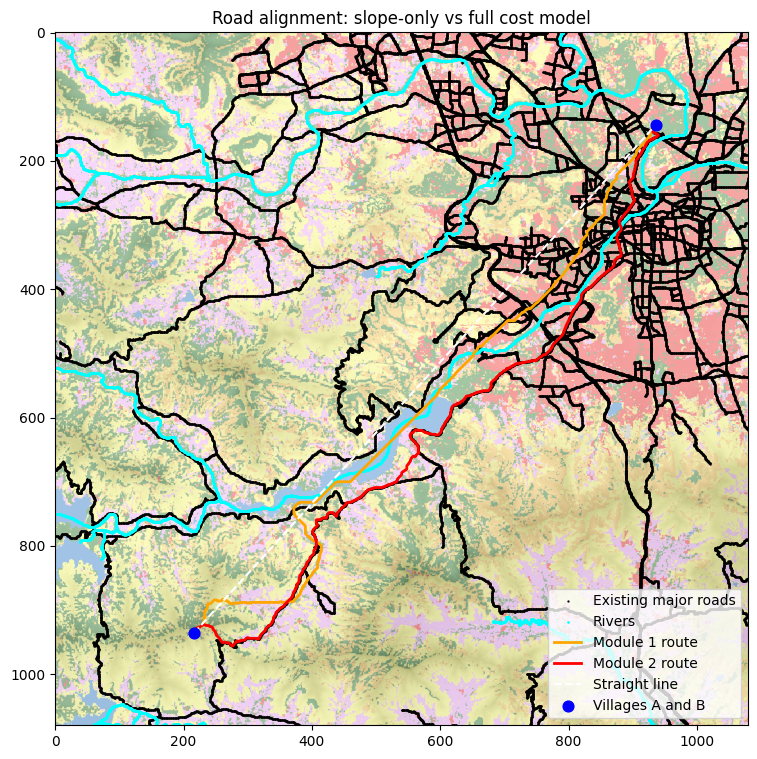

In [14]:
plt.figure(figsize=(10, 9))
plt.imshow(dem, cmap="Greys", alpha=0.5)
plt.imshow(lc_rgb, alpha=0.35)
ys, xs = np.where(road_mask)
plt.scatter(xs, ys, s=0.4, c="black", label="Existing major roads")
ys, xs = np.where(river_mask)
plt.scatter(xs, ys, s=0.8, c="cyan", label="Rivers")
plt.plot(path1[:, 1], path1[:, 0], color="orange", linewidth=2, label="Module 1 route")
plt.plot(path2[:, 1], path2[:, 0], color="red", linewidth=2, label="Module 2 route")
plt.plot([c1, c2], [r1, r2], "w--", linewidth=1.5, label="Straight line")
plt.scatter([c1, c2], [r1, r2], c="blue", s=60, zorder=5, label="Villages A and B")
plt.legend(loc="lower right")
plt.title("Road alignment: slope-only vs full cost model")
plt.savefig("module2_route.png", dpi=150, bbox_inches="tight")
plt.show()

                       Straight line  Module 1 (slope only)  Module 2 (slope+land+rivers)  Module 2b (new build)
Length (km)                33.100000                   38.1                     41.700000                   45.4
Average slope (deg)         8.000000                    3.1                      6.200000                    5.4
Steepest (deg)             41.900002                   28.1                     34.900002                   28.1
% steeper than 15 deg      18.800000                    2.8                      8.700000                    4.2
% through forest           23.400000                   22.4                     23.500000                    5.6
% through cropland          7.200000                   17.1                      9.300000                   10.1
Built-up pixels           116.000000                  198.0                    431.000000                   11.0
Water pixels               37.000000                  210.0                      5.000000       

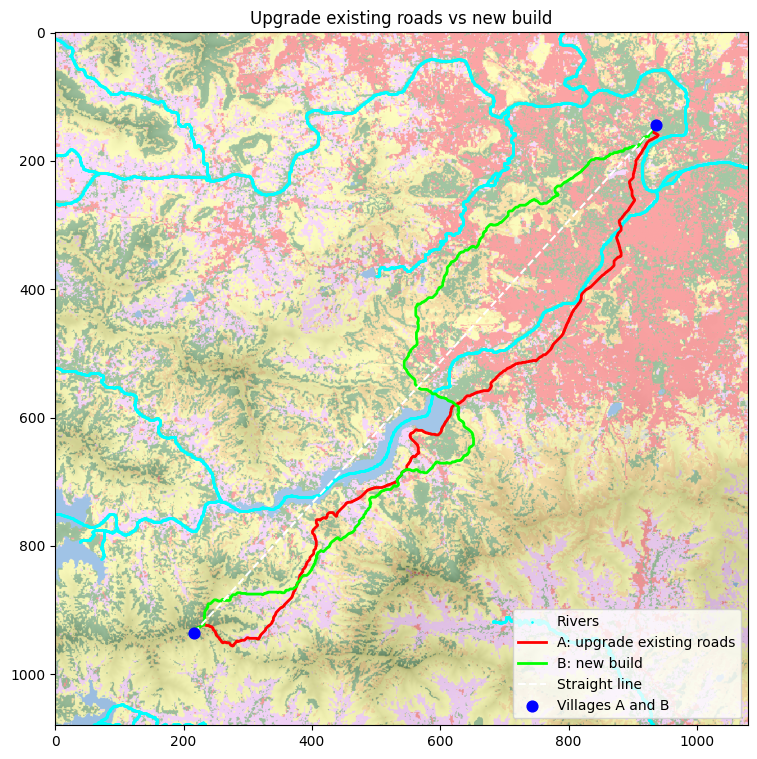

In [15]:
# Scenario B: new road, ignoring existing roads
cost3 = slope_cost + lc_add
cost3[river_mask] += 30

path3, _ = route_through_array(cost3, (r1, c1), (r2, c2),
                               fully_connected=True, geometric=True)
path3 = np.array(path3)

table["Module 2b (new build)"] = pd.Series(metrics(path3[:, 0], path3[:, 1]))
print(table.to_string())

plt.figure(figsize=(10, 9))
plt.imshow(dem, cmap="Greys", alpha=0.5)
plt.imshow(lc_rgb, alpha=0.35)
ys, xs = np.where(river_mask)
plt.scatter(xs, ys, s=0.8, c="cyan", label="Rivers")
plt.plot(path2[:, 1], path2[:, 0], color="red", linewidth=2, label="A: upgrade existing roads")
plt.plot(path3[:, 1], path3[:, 0], color="lime", linewidth=2, label="B: new build")
plt.plot([c1, c2], [r1, r2], "w--", linewidth=1.5, label="Straight line")
plt.scatter([c1, c2], [r1, r2], c="blue", s=60, zorder=5, label="Villages A and B")
plt.legend(loc="lower right")
plt.title("Upgrade existing roads vs new build")
plt.savefig("module2b_route.png", dpi=150, bbox_inches="tight")
plt.show()